# Predicting When Halifax Buses Leave People Behind

**CSCI 6505 — Machine Learning, Dalhousie University · final walkthrough**

This notebook tells the whole project as one story, from the raw data to the conclusion. It is written for CS students who have not taken a machine-learning course. Every step says **what** we do, **why** we do it, and **what the result means**.

**The short version**
- We can predict which bus routes and times of day are likely to leave riders behind, clearly better than simple rules of thumb.
- The most useful clue is whether it **has been happening there recently**.
- Weather, the university calendar and detailed ridership numbers did **not** improve the predictions.

**Contents**
1. The problem
2. Turning it into a machine-learning question
3. The data
4. Exploring the data
5. Building the table we learn from
6. Testing fairly: no peeking at the future
7. How we measure "good"
8. Simple rules to beat
9. First models
10. Does weather help?
11. Three more ideas
12. Is the improvement real, or luck?
13. The final model in action
14. What does the model look at?
15. Limitations
16. Results at a glance
17. Conclusion

> **How to run:** use the project's `.venv` kernel, after running the data pipeline (`src/load.py`, `src/build_panel.py`, `src/weather.py`, `src/features.py`; see the README). Running everything takes about 1–2 minutes.

In [1]:
# Setup: libraries, file paths and a consistent chart style
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch, Rectangle
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.metrics import average_precision_score, precision_recall_curve
warnings.simplefilter("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, REP = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "reports"
needed = [PROC / f for f in ["overloads.parquet", "apc.parquet", "panel.parquet", "panel_features.parquet"]]
missing = [str(p) for p in needed if not p.exists()]
assert not missing, f"Run the data pipeline first (see README). Missing: {missing}"

BLUE, ORANGE, AQUA, YELLOW, PINK, GREEN, VIOLET, RED = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURF, GRAY = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb", "#a3a29b"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "lines.linewidth": 2, "legend.frameon": False,
    "figure.dpi": 110, "font.size": 10})
pd.set_option("display.width", 200)
print("ready")

ready


## 1. The problem

When a Halifax Transit bus is full, the driver has to **drive past people waiting at the stop**. Halifax Transit calls this a **passenger overload** and logs each one: when, on which route, and where. In September 2026 the city published these records for the first time.

For riders this means being late for class or work, or waiting in the cold for the next bus. If Halifax Transit knew **in advance** where and when overloads are likely, it could add a bus or adjust the schedule *before* people are left behind.

## 2. Turning it into a machine-learning question

"Predict overloads" is too vague for a computer, so we pin down exactly what we predict.

- **Unit of prediction:** one **route** × one **weekday** × one **time period**. The periods are morning (6–10), midday (10–14), afternoon (14–19) and evening (19–24).
- **Answer:** **yes or no**: will there be at least one overload in that cell? A yes/no question is called **classification**.
- **Scope:** weekdays only (no weekends or holidays), and the **10 routes** with the most overloads. Together they account for 81% of all incidents.

So every weekday gives us 10 routes × 4 periods = **40 small yes/no questions**. For example: *"Route 3, Tuesday Sept 15, afternoon: will a bus leave someone behind?"*

**Why this framing?** It matches how a transit planner thinks: "which routes and times need an extra bus?" Grouping by period, rather than predicting each individual bus trip, also keeps the problem manageable.

## 3. The data

We combined three free, public datasets.

| Dataset | From | What one row means |
|---|---|---|
| Passenger overload incidents (9,354 rows, 2020 – Oct 2026) | [Halifax open data](https://data-hrm.hub.arcgis.com/datasets/HRM::transit-passenger-overload-incidents/about) | one bus drove past waiting riders |
| Automated passenger counts (9.1 million rows, 2017 – Nov 2026) | [Halifax open data](https://data-hrm.hub.arcgis.com/datasets/HRM::transit-automated-passenger-counts/about) | how many people boarded one route, in one direction, in one half hour |
| Weather (Dec 2021 – Oct 2026) | [Environment Canada](https://climate.weather.gc.ca/historical_data/search_historic_data_e.html), Halifax airport | temperature, wind, rain, snow per hour or day |

We also built a small **university calendar** (term start, study breaks, exams) from Dalhousie's official academic calendars.

Here is what the raw files look like:

In [2]:
raw_ovl = pd.read_csv(RAW / "overloads" / "overload_incidents.csv", encoding="utf-8-sig", nrows=5)
raw_apc = pd.read_csv(RAW / "apc" / "apc_2026.csv", nrows=5)
print("Overload incidents (raw):"); display(raw_ovl)
print("Passenger counts (raw):"); display(raw_apc)

Overload incidents (raw):


,OBJECTID,INCIDENT_REPORT_ID,DATETIME_OCURRED,ROUTE_NUMBER,LATITUDE,LONGITUDE,INCIDENT_OVERLOAD
0,1,136867,1/6/2020 7:20:55 PM,8,44.64053,-63.58647,Passenger Overload Start
1,2,136934,1/7/2020 7:21:15 PM,8,44.64056,-63.58649,Passenger Overload Start
2,3,136936,1/7/2020 7:36:09 PM,9A,44.64574,-63.59621,Passenger Overload Start
3,4,136942,1/7/2020 8:24:56 PM,4,44.65123,-63.59662,Passenger Overload Start
4,5,137081,1/9/2020 12:39:56 PM,9B,44.64560,-63.61526,Passenger Overload Start


Passenger counts (raw):


,OBJECTID,Route_Number,Route_Name,Route_Direction,Ridership_Total,Route_Hour,Route_Hour_Description,Route_Date
0,1,10B,Dalhousie - Micmac Terminal,Ind,18,6,6:00am to 6:29am,10/22/2026 10:00:00 AM
1,2,10C,Dalhousie,Ind,31,6,6:00am to 6:29am,10/22/2026 10:00:00 AM
2,3,10C,Dalhousie,Oud,78,6,6:00am to 6:29am,10/22/2026 10:00:00 AM
3,4,127,Cowie Hill Express,Ind,16,6,6:00am to 6:29am,10/22/2026 10:00:00 AM
4,5,135,Flamingo Express,Ind,32,6,6:00am to 6:29am,10/22/2026 10:00:00 AM


### Cleaning the data

Raw data is rarely ready to use. Before doing anything else, we fixed these problems (code in `src/load.py`):

1. **Time zones.** Overload times are stored in **UTC** (London time), not Halifax time. A bus at 3 pm in Halifax shows up as 7 pm, which would make it look like an evening problem.
2. **Ferries.** The overload file also contains ferry incidents; we removed those (24 rows), plus 2 locations far outside Halifax.
3. **After-midnight buses.** The passenger counts write 12:30 am as "hour 24.5", meaning it still belongs to the *previous* service day. We matched overloads to the same convention.
4. **Sensor glitches.** A few half-hours claimed thousands of boardings, e.g. 7,883 people in 30 minutes on one route. We marked 161 such impossible values as *missing* rather than trusting them.
5. **Missing is not zero.** If a counter recorded nothing, we treat it as "unknown", not "nobody rode".

Here is the time-zone fix on the first five incidents:

In [3]:
t = pd.to_datetime(raw_ovl.DATETIME_OCURRED, format="%m/%d/%Y %I:%M:%S %p").dt.tz_localize("UTC")
pd.DataFrame({"route": raw_ovl.ROUTE_NUMBER,
              "as stored (UTC)": t.dt.strftime("%a %b %d %Y, %I:%M %p"),
              "Halifax time": t.dt.tz_convert("America/Halifax").dt.strftime("%a %b %d %Y, %I:%M %p")})

,route,as stored (UTC),Halifax time
0,8,"Mon Jan 06 2020, 07:20 PM","Mon Jan 06 2020, 03:20 PM"
1,8,"Tue Jan 07 2020, 07:21 PM","Tue Jan 07 2020, 03:21 PM"
2,9A,"Tue Jan 07 2020, 07:36 PM","Tue Jan 07 2020, 03:36 PM"
3,4,"Tue Jan 07 2020, 08:24 PM","Tue Jan 07 2020, 04:24 PM"
4,9B,"Thu Jan 09 2020, 12:39 PM","Thu Jan 09 2020, 08:39 AM"


Every incident moves 4–5 hours earlier, into the afternoon rush, which makes much more sense. Now we load the cleaned data:

In [4]:
ovl = pd.read_parquet(PROC / "overloads.parquet")
print(f"{len(ovl):,} bus overload incidents, {ovl.datetime_local.min():%b %Y} to {ovl.datetime_local.max():%b %Y}")
ovl[["datetime_local", "route", "period", "lat", "lon"]].head()

9,328 bus overload incidents, Jan 2020 to Oct 2026


,datetime_local,route,period,lat,lon
0,2020-01-06 15:20:55-04:00,8,PM,44.64053,-63.58647
1,2020-01-07 15:21:15-04:00,8,PM,44.64056,-63.58649
2,2020-01-07 15:36:09-04:00,9A,PM,44.64574,-63.59621
3,2020-01-07 16:24:56-04:00,4,PM,44.65123,-63.59662
4,2020-01-09 08:39:56-04:00,9B,AM,44.64560,-63.61526


## 4. Exploring the data

Before building any model, we **look at the data**. This is called exploratory data analysis. It tells us what patterns exist, what could go wrong, and which clues might be useful.

### When in the year do overloads happen?

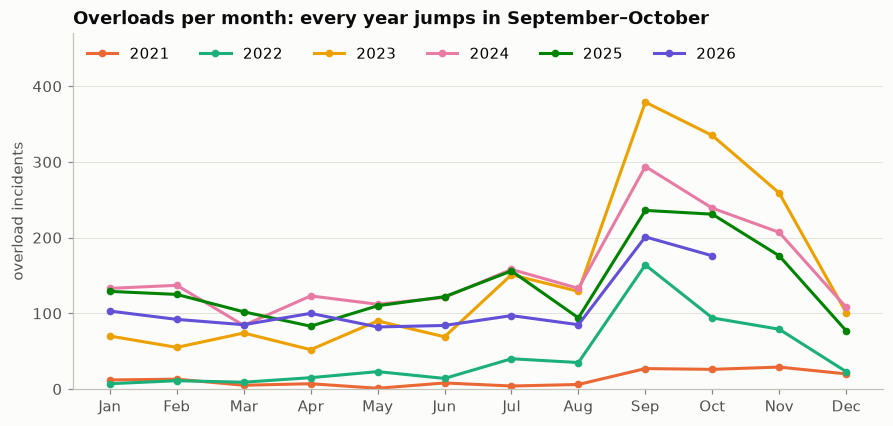

2020 (left out of the chart): {1: 77, 2: 34, 3: 16, 4: 27, 5: 754, 6: 586, 7: 765, 9: 10, 10: 8, 11: 19, 12: 1}


In [5]:
m = ovl.assign(month=ovl.service_date.dt.month).groupby(["year", "month"]).size().unstack(0).reindex(range(1, 13))
m.loc[11:, 2026] = np.nan          # data ends Oct 30, 2026
fig, ax = plt.subplots(figsize=(9.5, 4.2))
cols = {2021: ORANGE, 2022: AQUA, 2023: YELLOW, 2024: PINK, 2025: GREEN, 2026: VIOLET}
for y, c in cols.items():
    ax.plot(m.index, m[y], marker="o", ms=4, color=c, label=str(y))
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("overload incidents"); ax.set_ylim(0, 470); ax.legend(ncol=6, loc="upper left")
ax.set_title("Overloads per month: every year jumps in September–October")
plt.show()
print("2020 (left out of the chart):", ovl[ovl.year == 2020].groupby(ovl.service_date.dt.month).size().to_dict())

**What this tells us**
- **Every year jumps in September and October,** when university classes start and thousands of students start riding.
- **2020 is strange.** Almost all its incidents fall in May–July 2020, when COVID rules limited how many people could ride a bus, so buses were "full" with only a few riders. 2020 is unlike every other year, so we **leave it out of the modelling**.
- **2021–2022 are low**, as ridership was still recovering from COVID.

### What time of day, and which day of the week?

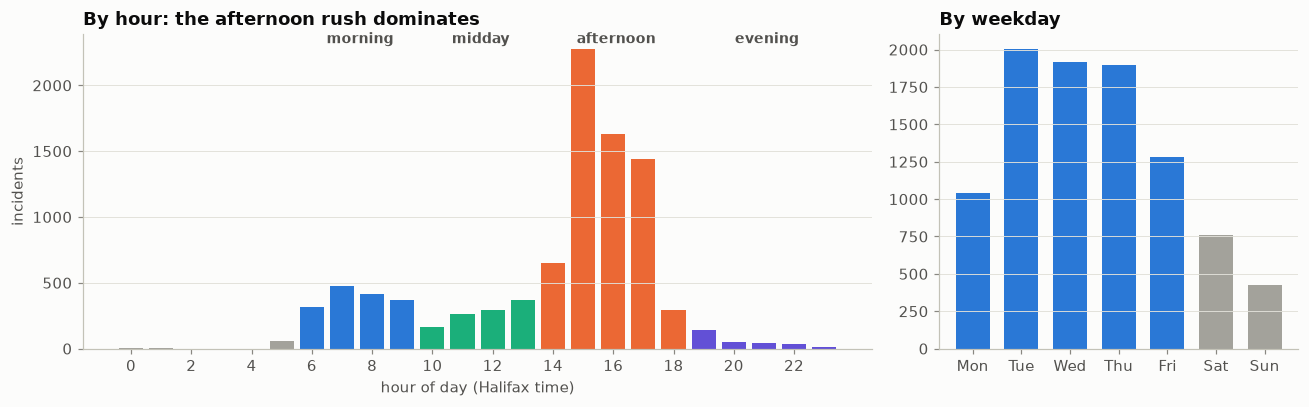

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
h = ovl.groupby("clock_hour").size().reindex(range(24), fill_value=0)
pcol = {**{k: BLUE for k in range(6, 10)}, **{k: AQUA for k in range(10, 14)}, **{k: ORANGE for k in range(14, 19)}, **{k: VIOLET for k in range(19, 24)}}
a1.bar(h.index, h.values, width=0.8, color=[pcol.get(k, GRAY) for k in h.index])
for lab, x in [("morning", 8), ("midday", 12), ("afternoon", 16.5), ("evening", 21.5)]:
    a1.text(x - 0.4, h.max() * 1.02, lab, ha="center", fontsize=9, color=INK2, fontweight="bold")
a1.set_xticks(range(0, 24, 2)); a1.set_xlabel("hour of day (Halifax time)"); a1.set_ylabel("incidents")
a1.set_title("By hour: the afternoon rush dominates")
wd = ovl.groupby("weekday").size()
a2.bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], wd.values, width=0.7, color=[BLUE]*5 + [GRAY]*2)
a2.set_title("By weekday")
fig.tight_layout(); plt.show()

**What this tells us**
- **Overloads peak between 3 and 5 pm,** when school, university and work let out at the same time.
- **Tuesday to Thursday have about twice the incidents of Monday or Friday.** Many university classes run Tue–Thu, and some people work from home on Mondays and Fridays.
- **Weekends are much quieter,** which is why we focus on weekdays.

### Which routes, and where?

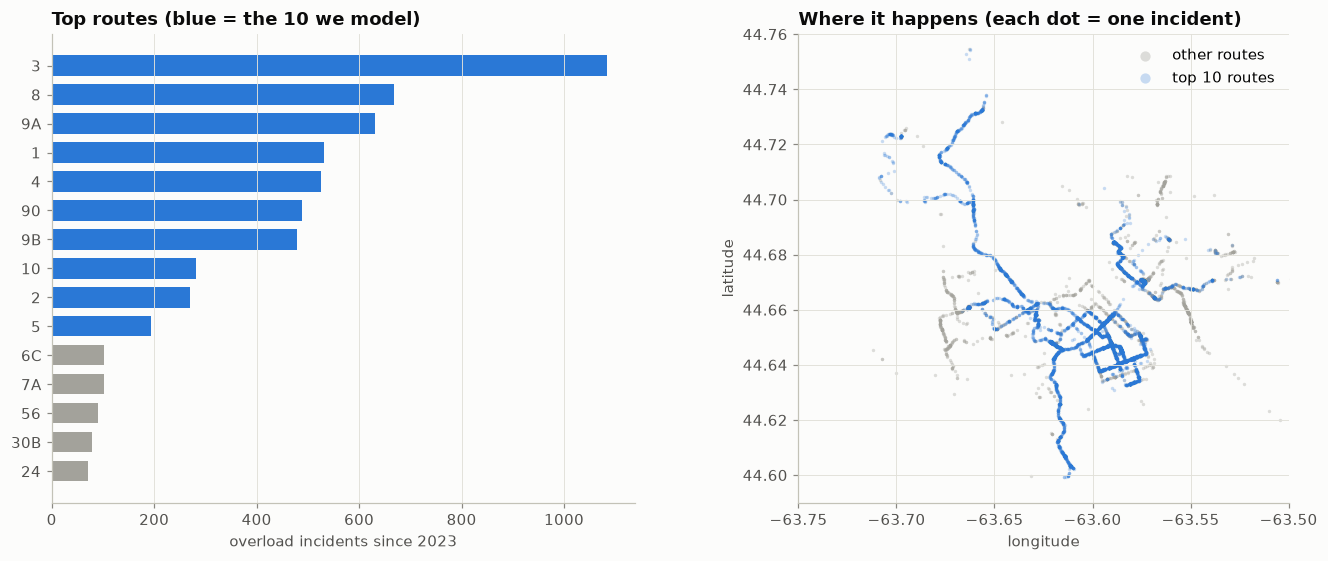

The top 10 routes (3, 8, 9A, 1, 4, 90, 9B, 10, 2, 5) account for 81% of incidents since 2023.


In [7]:
since = ovl[ovl.service_date >= "2023-01-01"].groupby("route_group").size().sort_values(ascending=False)
top10 = since.head(10).index.tolist()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1, 1.25]})
s = since.head(15)[::-1]
a1.barh(s.index, s.values, height=0.7, color=[BLUE if r in top10 else GRAY for r in s.index])
a1.grid(axis="y", visible=False); a1.grid(axis="x", visible=True)
a1.set_xlabel("overload incidents since 2023"); a1.set_title("Top routes (blue = the 10 we model)")
other, top = ovl[~ovl.route_group.isin(top10)], ovl[ovl.route_group.isin(top10)]
a2.scatter(other.lon, other.lat, s=5, alpha=0.35, color=GRAY, linewidths=0, label="other routes")
a2.scatter(top.lon, top.lat, s=5, alpha=0.25, color=BLUE, linewidths=0, label="top 10 routes")
a2.set_xlim(-63.75, -63.5); a2.set_ylim(44.59, 44.76); a2.set_aspect(1 / np.cos(np.deg2rad(44.65)))
a2.grid(True, axis="both"); a2.legend(markerscale=3, loc="upper right"); a2.set_title("Where it happens (each dot = one incident)")
a2.set_xlabel("longitude"); a2.set_ylabel("latitude")
fig.tight_layout(); plt.show()
print(f"The top 10 routes ({', '.join(top10)}) account for {since.head(10).sum() / since.sum():.0%} of incidents since 2023.")

**What this tells us.** Overloads are **concentrated on a few routes**, along the main corridors into the Halifax peninsula and around the universities. Route 3 alone has about one in six incidents since 2023 (17%). So we focus on the 10 worst routes.

### Ridership vs overloads over the years

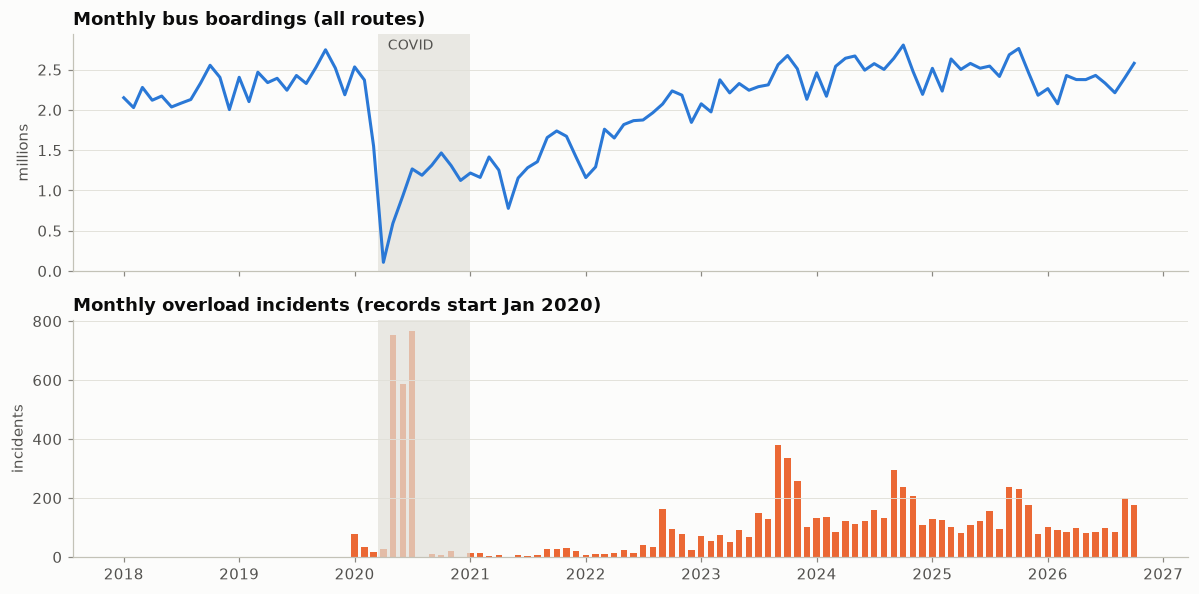

In [8]:
apc_m = (pd.read_parquet(PROC / "apc.parquet", columns=["service_date", "ridership"])
           .groupby(pd.Grouper(key="service_date", freq="MS")).ridership.sum() / 1e6)
ovl_m = ovl.groupby(pd.Grouper(key="service_date", freq="MS")).size()
apc_m = apc_m[(apc_m.index >= "2018-01-01") & (apc_m.index <= "2026-10-01")]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
a1.plot(apc_m.index, apc_m.values, color=BLUE); a1.set_ylim(0); a1.set_ylabel("millions"); a1.set_title("Monthly bus boardings (all routes)")
a2.bar(ovl_m.index, ovl_m.values, width=20, color=ORANGE); a2.set_ylabel("incidents"); a2.set_title("Monthly overload incidents (records start Jan 2020)")
for a in (a1, a2): a.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2020-12-31"), color=GRID, alpha=0.7, lw=0)
a1.text(pd.Timestamp("2020-04-15"), 2.75, "COVID", color=INK2, fontsize=9)
fig.tight_layout(); plt.show()

**What this tells us**
- **Ridership** collapsed in 2020 and only returned to pre-COVID levels around 2023.
- **Overloads** became much more common from 2023 onward. Incidents per million boardings roughly tripled from 2022 to 2023, which could be real crowding or a change in how drivers report.
- **The yearly level moves around,** and a good model has to cope with that.

## 5. Building the table we learn from

Machine-learning models learn from a **table**: one row per example, columns of **features** (the clues), and one **label** (the answer).

- **Rows:** one per route × weekday × period, from 2020 to October 2026, skipping weekends and holidays.
- **Label `y`:** 1 if at least one overload happened in that cell, else 0.
- **Features:** information about the cell that we could know *before that day*. For example: which route, which period, the day of the week, the month, how many people rode last week, last week's weather, whether overloads happened recently.

The table was built by `src/build_panel.py`, `src/weather.py` and `src/features.py`. Here are a few rows:

In [9]:
full = pd.read_parquet(PROC / "panel.parquet")                 # 2020 onward (used for look-backs)
df = pd.read_parquet(PROC / "panel_features.parquet")          # 2022 onward, with all features
for c in ["route", "period"]:
    full[c] = full[c].astype(str)
# "same as last week" answer (used by a simple rule in section 8): y on the previous non-holiday same weekday
full = full.sort_values(["route", "period", "dow", "date"])
full["y_last_week"] = full.groupby(["route", "period", "dow"]).y.shift(1)
df = df.merge(full[["route", "period", "date", "y_last_week"]].assign(route=lambda d: d.route.astype(df.route.dtype),
              period=lambda d: d.period.astype(df.period.dtype)), on=["route", "period", "date"], how="left")
df["route_period"] = df.route.astype(str) + "_" + df.period.astype(str)
print(f"{len(df):,} rows (2022 – Oct 2026), {df.shape[1]} columns")
df[["date", "route", "period", "dow", "month", "boardings_lag1w", "temp_mean", "ovl_days_prev5", "in_term", "y"]].sample(6, random_state=3).sort_values("date")

48,080 rows (2022 – Oct 2026), 45 columns


,date,route,period,dow,month,boardings_lag1w,temp_mean,ovl_days_prev5,in_term,y
5862,2022-08-03,90,PM,2,8,684.0,27.100,0.0,0,0
14777,2023-06-27,4,MID,1,6,1074.0,16.200,0.0,0,0
20691,2024-02-01,9A,EVE,3,2,487.0,-0.580,0.0,1,0
27921,2024-10-23,3,MID,2,10,1786.0,14.200,0.0,1,0
41780,2026-03-16,90,AM,0,3,962.0,-0.125,0.0,1,0
46153,2026-08-20,2,MID,3,8,1075.0,21.800,1.0,0,0


Share of cells with an overload: 7.8%  (about 1 in 13)


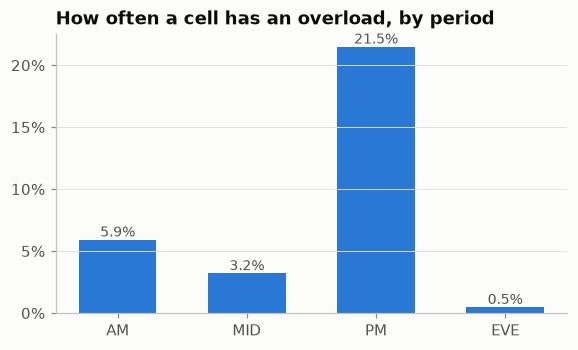

In [10]:
print(f"Share of cells with an overload: {df.y.mean():.1%}  (about 1 in {1 / df.y.mean():.0f})")
r = df.groupby("period", observed=True).y.mean()
fig, ax = plt.subplots(figsize=(6, 3.3))
ax.bar(r.index.astype(str), r.values, width=0.6, color=BLUE)
for i, v in enumerate(r.values): ax.text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_title("How often a cell has an overload, by period")
plt.show()

**What this tells us.** Only about **1 in 13 cells** has an overload; most of the time, everything is fine. This is called an **imbalanced** problem. It matters for how we measure success (section 7): a lazy model that always says "no" would be right 92% of the time and completely useless.

## 6. Testing fairly: no peeking at the future

The most common mistake in machine learning is accidentally letting the model **see the answer**. We guard against it in two ways.

**1. Split by time.** The model learns from the past and is tested on the future, just as it would be used in real life:

| Part | Years | Used for |
|---|---|---|
| **Training** | 2022–2024 | the model learns patterns here |
| **Validation** | 2025 | we compare options and choose settings here |
| **Test** | Jan–Oct 2026 | the final exam: used only at the end, never for choosing |

A random shuffle would let the model learn from, say, October 2026 and then "predict" September 2026. That is unrealistic and makes results look better than they are.

**2. Only use information from *before* the day.** Every feature looks backwards: last week's ridership, last week's overloads, and so on. We deliberately do **not** use how many people boarded during the same period. When a bus leaves people behind, they board the *next* bus, so same-period boardings are partly a *result* of the overload. Using them would be cheating.

(Weather is the one exception. We use the actual weather of the day, pretending we had a perfect forecast. That gives weather its best possible chance.)

In [11]:
df["split"] = np.select([df.year <= 2024, df.year == 2025, df.year == 2026], ["train", "validation", "test"], "other")
train, val, test = (df[df.split == s].reset_index(drop=True) for s in ["train", "validation", "test"])
pd.DataFrame({"rows": [len(train), len(val), len(test)],
              "share with an overload": [train.y.mean(), val.y.mean(), test.y.mean()]},
             index=["train 2022–24", "validation 2025", "test 2026"]).round(3)

,rows,share with an overload
train 2022–24,29800,0.071
validation 2025,9960,0.096
test 2026,8320,0.079


The overload rate changes from year to year: 7.1% in training, 9.6% in 2025, 7.9% in 2026. That makes the test harder, because the future doesn't look exactly like the past.

## 7. How we measure "good"

Because overloads are rare, plain **accuracy** is misleading (see section 5). Instead, each model gives every cell a **risk score**, and we ask how well it **ranks** the real overloads near the top of its list.

- **Precision:** of the cells we flag, how many really had an overload? (Few false alarms.)
- **Recall:** of all real overloads, how many did we flag? (Few misses.)
- **PR-AUC** (precision–recall area under the curve) summarises the trade-off between the two across all possible thresholds, as a single number between 0 and 1. Higher is better. Random guessing scores about the overload rate (≈ 0.08 in 2026).
- **"Top 5%" check:** if Halifax Transit could act on only the riskiest 5% of cells (about 2 of the 40 each day), how many overloads would that catch?

In [12]:
def evaluate(d, score, name):
    """PR-AUC + what a 'flag the riskiest 5%' policy would catch (ties broken at random, fixed seed)."""
    y, s = d.y.to_numpy(), np.asarray(score, dtype=float)
    order = np.lexsort((np.random.default_rng(0).random(len(s)), -s))
    top = order[: int(np.ceil(0.05 * len(s)))]
    return {"model": name, "PR-AUC": round(average_precision_score(y, s), 3),
            "overloads caught (top 5%)": int(y[top].sum()), "out of": int(y.sum()),
            "share caught": round(y[top].sum() / y.sum(), 3), "flags that were right": round(y[top].mean(), 3)}
print("evaluate() ready")

evaluate() ready


## 8. Simple rules to beat

A model is only worth building if it beats **simple common-sense rules**. Rules like these are called **baselines**. We use two:

1. **"Same as last week":** if there was an overload in this cell on the same weekday last week, predict yes.
2. **"Historical rate":** how often did this route + period have an overload in this month in the training years? For example, Route 3 afternoons in September had an overload X% of the time, so that's the risk score.

In [13]:
def hist_rate(train, target):
    r3 = train.groupby(["route", "period", "month"], observed=True).y.mean().rename("r3")
    r2 = train.groupby(["route", "period"], observed=True).y.mean().rename("r2")
    t = target.join(r3, on=["route", "period", "month"]).join(r2, on=["route", "period"])
    return t.r3.fillna(t.r2).fillna(train.y.mean()).to_numpy()

results = {"validation": [], "test": []}
scores = {"validation": {}, "test": {}}
for split, d in [("validation", val), ("test", test)]:
    rnd = np.random.default_rng(1).random(len(d))
    for name, s in [("Random guessing", rnd), ("Same as last week", d.y_last_week.fillna(0).to_numpy()),
                    ("Historical rate", hist_rate(train, d))]:
        scores[split][name] = s; results[split].append(evaluate(d, s, name))
pd.DataFrame(results["test"]).set_index("model")

,PR-AUC,overloads caught (top 5%),out of,share caught,flags that were right
model,,,,,
Random guessing,0.084,44,656,0.067,0.106
Same as last week,0.141,129,656,0.197,0.310
Historical rate,0.249,135,656,0.206,0.325


**What this tells us.** On 2026, the historical-rate rule already does about three times better than random guessing (PR-AUC 0.249 vs about 0.08). "Same as last week" is much weaker. These are the numbers our models have to beat.

## 9. First models

We try two kinds of model:

- **Logistic regression:** the classic statistical model. It gives each clue a weight, adds them up and squashes the total into a probability between 0 and 1. It is simple and easy to interpret, but it only adds effects together.
- **LightGBM** (gradient-boosted decision trees): builds hundreds of small **decision trees** ("if route = 3 and period = afternoon and month = September, then risk goes up…"). Each new tree fixes some of the previous trees' mistakes. It can pick up **combinations** of clues automatically.

Both models are told that overloads are rare (**class weighting**), so they don't just learn to say "no".

We start with only the "where and when" clues: **route, period, day of week, month** (feature set **A**). The model settings were chosen earlier on the 2025 validation year and are saved in `reports/`. Here we only refit and score.

In [14]:
TIME = ["route", "period", "dow", "month"]
LAGS = ["boardings_lag1w", "boardings_mean4w"]
WEATHER = ["temp_mean", "temp_min", "wind_mean", "wind_max", "vis_min", "wx_snow", "wx_rain", "wx_freezing",
           "precip_mm", "rain_mm", "snow_cm", "snow_ground_cm", "gust_max_kmh", "snow_cm_prev1d", "bad_weather"]
HISTORY = ["ovl_days_prev5", "ovl_weeks_prev4_sameday", "days_since_ovl"]
CALENDAR = ["in_term", "week_of_term", "is_first3w_fall", "is_break", "is_exam"]
RIDERSHIP = LAGS + ["peak_hh_lag1w", "peak_hh_mean4w", "peakdir_lag1w", "peakdir_mean4w", "yoy_ratio", "lag_ratio"]

settings = {**json.loads((REP / "model_selection.json").read_text()), **json.loads((REP / "r3_selection.json").read_text())}

def fit_lightgbm(features, s):
    y = train.y.astype("int32").to_numpy()
    m = lgb.LGBMClassifier(objective="binary", learning_rate=0.03, n_estimators=s["n_estimators"],
                           num_leaves=s["num_leaves"], min_child_samples=s["min_child_samples"],
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                           scale_pos_weight=(y == 0).sum() / (y == 1).sum(), random_state=0, verbose=-1, n_jobs=4)
    return m.fit(train[features], y)

def fit_logreg(features, s):
    cat = [c for c in TIME if c in features] + (["route_period"] if s["interact"] else [])
    counts = [c for c in features if c in RIDERSHIP and "ratio" not in c]
    ratios = [c for c in features if "ratio" in c]
    other = [c for c in features if c not in TIME and c not in RIDERSHIP]
    num = lambda f=None: Pipeline([("fill", SimpleImputer(strategy="median"))] +
                                  ([("log", FunctionTransformer(f, feature_names_out="one-to-one"))] if f else []) +
                                  [("scale", StandardScaler())])
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat)] +
                             ([("counts", num(np.log1p), counts)] if counts else []) +
                             ([("ratios", num(np.log), ratios)] if ratios else []) +
                             ([("other", num(), other)] if other else []))
    m = Pipeline([("prep", prep), ("clf", LogisticRegression(C=s["C"], class_weight="balanced", max_iter=5000))])
    return m.fit(train[features + (["route_period"] if s["interact"] else [])], train.y), features + (["route_period"] if s["interact"] else [])

def run_lightgbm(label, features, key):
    m = fit_lightgbm(features, settings[key])
    for split, d in [("validation", val), ("test", test)]:
        s = m.predict_proba(d[features])[:, 1]; scores[split][label] = s; results[split].append(evaluate(d, s, label))
    return m

lr, lr_cols = fit_logreg(TIME, settings["LogReg A_time"])
for split, d in [("validation", val), ("test", test)]:
    s = lr.predict_proba(d[lr_cols])[:, 1]; scores[split]["LogReg: where & when"] = s; results[split].append(evaluate(d, s, "LogReg: where & when"))
model_A = run_lightgbm("LightGBM A: where & when", TIME, "LightGBM A_time")
pd.DataFrame(results["test"]).set_index("model")

,PR-AUC,overloads caught (top 5%),out of,share caught,flags that were right
model,,,,,
Random guessing,0.084,44,656,0.067,0.106
Same as last week,0.141,129,656,0.197,0.310
Historical rate,0.249,135,656,0.206,0.325
LogReg: where & when,0.283,166,656,0.253,0.399
LightGBM A: where & when,0.292,159,656,0.242,0.382


**What this tells us.** Using only *where and when*, both models beat the historical-rate rule on 2026: PR-AUC about 0.28–0.29 vs 0.249. LightGBM is slightly ahead because it can combine clues, e.g. "this route is only bad on Tuesday afternoons in September". Section 12 checks whether this improvement is real or luck.

## 10. Does weather help?

This was our original question. The idea: bad weather might push more people onto buses (nobody wants to walk or cycle in the rain), or slow buses down so they bunch up and fill.

We add two groups to the where-and-when clues:
- **Recent ridership:** boardings in the same cell last week, and the average of the last 4 weeks.
- **Weather:** temperature, rain, snowfall, snow on the ground, wind.

In [15]:
run_lightgbm("LightGBM: + recent ridership", TIME + LAGS, "LightGBM B_lags")
run_lightgbm("LightGBM: + ridership + weather", TIME + LAGS + WEATHER, "LightGBM C_weather")
cmp = pd.DataFrame({s: pd.DataFrame(results[s]).set_index("model")["PR-AUC"] for s in ["validation", "test"]})
cmp.loc[["Historical rate", "LightGBM A: where & when", "LightGBM: + recent ridership", "LightGBM: + ridership + weather"]]

,validation,test
model,,
Historical rate,0.321,0.249
LightGBM A: where & when,0.372,0.292
LightGBM: + recent ridership,0.370,0.287
LightGBM: + ridership + weather,0.375,0.289


**What this tells us.** **No.** Adding ridership or weather barely changes the score. On 2026 it's slightly *lower* (0.292 → 0.287 → 0.289). Bad weather actually makes overloads slightly *less* likely, probably because fewer people travel in a storm. Even with a perfect weather forecast, the weather doesn't tell the model anything it doesn't already know from route, period and month.

## 11. Three more ideas

Since weather didn't help, we tried three other kinds of clue:

| Idea | Features | Why it might help |
|---|---|---|
| **Overload history** | overload days in the last 5 weekdays · overload weeks in the last 4 same-weekdays · days since the last overload | if a bus keeps filling up, the problem probably persists until the schedule changes |
| **University calendar** | in term? · week of term · first 3 weeks of fall · study break · exams | students are a big share of riders |
| **Better ridership** | busiest half-hour last week · busier direction · growth vs a year ago · "busier than usual?" | a sharper picture of demand than plain totals |

All of them only look backwards, and the look-backs skip holidays. Let's first check the raw signal in the training years:

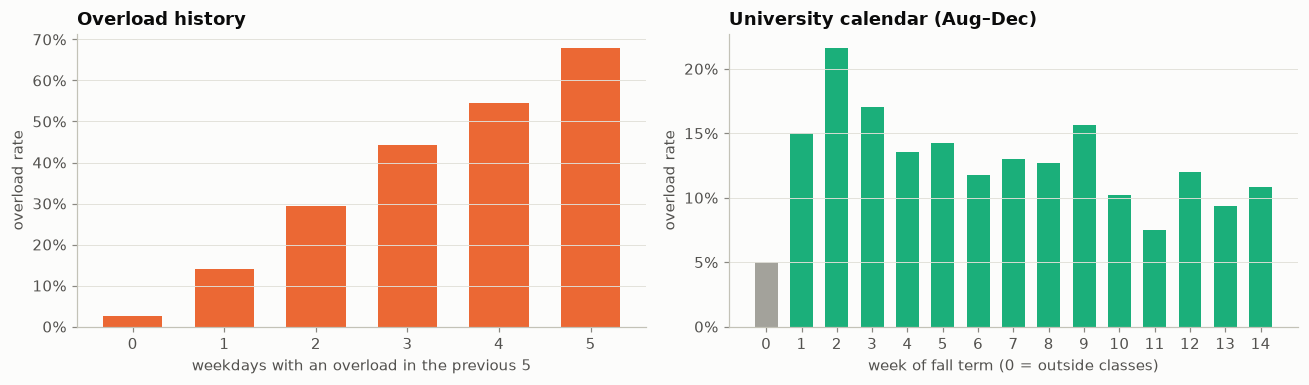

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
r = train.groupby("ovl_days_prev5").y.mean()
axes[0].bar(r.index.astype(int).astype(str), r.values, width=0.65, color=ORANGE)
axes[0].set_xlabel("weekdays with an overload in the previous 5"); axes[0].set_title("Overload history")
f = train[train.month.between(8, 12)]; r = f.groupby("week_of_term").y.mean()
axes[1].bar(r.index.astype(int).astype(str), r.values, width=0.65, color=[GRAY if w == 0 else AQUA for w in r.index])
axes[1].set_xlabel("week of fall term (0 = outside classes)"); axes[1].set_title("University calendar (Aug–Dec)")
for a in axes: a.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); a.set_ylabel("overload rate")
fig.tight_layout(); plt.show()

**What this tells us**
- **Overload history is a very strong clue.** With no overloads in the last 5 weekdays, the chance is about 3%. With an overload on all 5, it is about **68%**.
- **The calendar also shows a pattern:** the first weeks of fall term are much riskier. But "first weeks of fall term" mostly means "September", which the model already knows from the month. The question is whether a clue adds anything **on top of** what the model already knows.

Now the real test: we add each idea to the where-and-when model.

In [17]:
run_lightgbm("LightGBM: + overload history", TIME + HISTORY, "LightGBM B_history")
run_lightgbm("LightGBM: + university calendar", TIME + CALENDAR, "LightGBM C_calendar")
run_lightgbm("LightGBM: + better ridership", TIME + RIDERSHIP, "LightGBM D_ridership")
run_lightgbm("LightGBM: + all three", TIME + HISTORY + CALENDAR + RIDERSHIP, "LightGBM E_all3")
final_features = TIME + HISTORY + CALENDAR + RIDERSHIP + WEATHER
final_model = run_lightgbm("LightGBM: everything (final)", final_features, "LightGBM F_all3_weather")
lr_f, lr_f_cols = fit_logreg(final_features, settings["LogReg F_all3_weather"])
for split, d in [("validation", val), ("test", test)]:
    s = lr_f.predict_proba(d[lr_f_cols])[:, 1]; scores[split]["LogReg: everything"] = s; results[split].append(evaluate(d, s, "LogReg: everything"))

order = ["Random guessing", "Same as last week", "Historical rate", "LightGBM A: where & when",
         "LightGBM: + recent ridership", "LightGBM: + ridership + weather", "LightGBM: + university calendar",
         "LightGBM: + better ridership", "LightGBM: + overload history", "LightGBM: + all three",
         "LightGBM: everything (final)", "LogReg: where & when", "LogReg: everything"]
table = pd.DataFrame({s: pd.DataFrame(results[s]).set_index("model")["PR-AUC"] for s in ["validation", "test"]}).loc[order]
table

,validation,test
model,,
Random guessing,0.098,0.084
Same as last week,0.165,0.141
Historical rate,0.321,0.249
LightGBM A: where & when,0.372,0.292
LightGBM: + recent ridership,0.370,0.287
LightGBM: + ridership + weather,0.375,0.289
LightGBM: + university calendar,0.364,0.299
LightGBM: + better ridership,0.371,0.290
LightGBM: + overload history,0.392,0.360


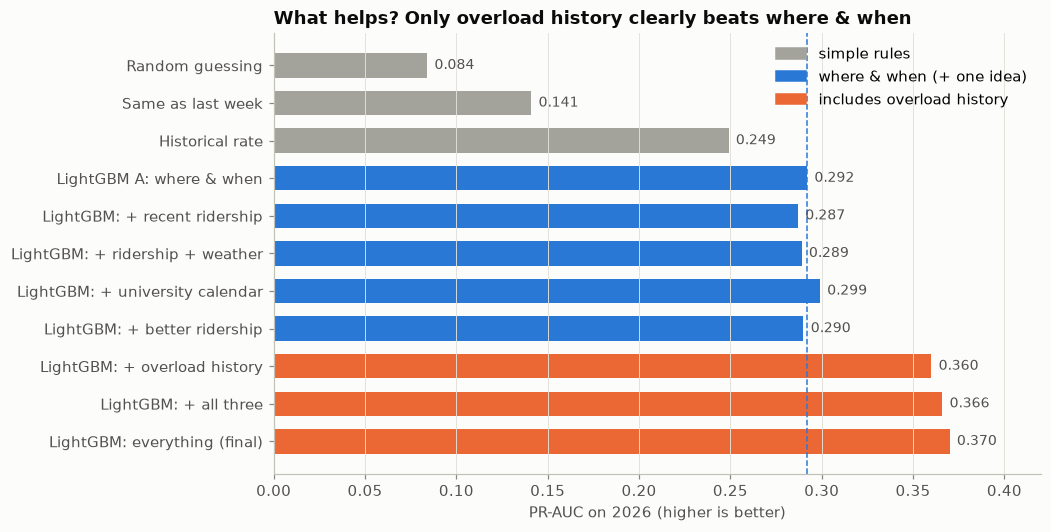

In [18]:
t = table["test"].drop(["LogReg: where & when", "LogReg: everything"])
colors = [GRAY if n in ("Random guessing", "Same as last week", "Historical rate")
          else ORANGE if ("history" in n or "all three" in n or "everything" in n) else BLUE for n in t.index]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(t.index[::-1], t.values[::-1], height=0.65, color=colors[::-1])
for y_, v in enumerate(t.values[::-1]): ax.text(v + 0.004, y_, f"{v:.3f}", va="center", fontsize=9, color=INK2)
ax.axvline(t["LightGBM A: where & when"], color=BLUE, ls="--", lw=1)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True); ax.set_xlim(0, 0.42)
ax.set_xlabel("PR-AUC on 2026 (higher is better)")
ax.set_title("What helps? Only overload history clearly beats where & when")
ax.legend(handles=[Patch(color=GRAY, label="simple rules"), Patch(color=BLUE, label="where & when (+ one idea)"),
                   Patch(color=ORANGE, label="includes overload history")], loc="upper right")
plt.show()

**What this tells us**
- **Overload history is the only idea that clearly helps:** PR-AUC jumps from 0.292 to 0.360 on 2026.
- **The calendar and better ridership barely move the score.** Their information is already captured by route, period and month.
- **Adding everything** reaches 0.370, only a little above history alone (0.360).
- **Logistic regression shows the same pattern** (0.283 → 0.365). So this is a property of the data, not a quirk of one model.

## 12. Is the improvement real, or luck?

The test year has only 656 overload cells, so some differences could be luck. To check, we use the **bootstrap**:

1. Re-draw the 2026 test days at random, with replacement, 1,000 times, so each draw is a slightly different "alternative 2026".
2. Recompute the difference between two models on each draw.
3. If the middle 95% of those differences stays above zero, the improvement is unlikely to be luck. That range is the **95% confidence interval**.

We resample whole days, because the 40 cells of one day are related: a snowstorm affects them all.

In [19]:
def bootstrap_gain(d, s_old, s_new, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    days, inv = np.unique(d.date.to_numpy(), return_inverse=True)
    rows_of = [np.flatnonzero(inv == i) for i in range(len(days))]
    y, a, b = d.y.to_numpy(), np.asarray(s_old), np.asarray(s_new)
    gains = []
    for _ in range(n):
        k = np.concatenate([rows_of[i] for i in rng.integers(0, len(days), len(days))])
        gains.append(average_precision_score(y[k], b[k]) - average_precision_score(y[k], a[k]))
    lo, hi = np.percentile(gains, [2.5, 97.5])
    return average_precision_score(y, b) - average_precision_score(y, a), lo, hi

S = scores["test"]
checks = [("where & when  vs  historical rate", "Historical rate", "LightGBM A: where & when"),
          ("+ weather  vs  + ridership", "LightGBM: + recent ridership", "LightGBM: + ridership + weather"),
          ("+ calendar  vs  where & when", "LightGBM A: where & when", "LightGBM: + university calendar"),
          ("+ overload history  vs  where & when", "LightGBM A: where & when", "LightGBM: + overload history"),
          ("everything  vs  + overload history", "LightGBM: + overload history", "LightGBM: everything (final)"),
          ("final model  vs  historical rate", "Historical rate", "LightGBM: everything (final)")]
rows = []
for label, old, new in checks:
    g, lo, hi = bootstrap_gain(test, S[old], S[new])
    rows.append({"comparison (test 2026)": label, "PR-AUC gain": round(g, 3), "95% CI low": round(lo, 3), "95% CI high": round(hi, 3),
                 "verdict": "real improvement" if lo > 0 else ("worse" if hi < 0 else "could be luck")})
pd.DataFrame(rows).set_index("comparison (test 2026)")

,PR-AUC gain,95% CI low,95% CI high,verdict
comparison (test 2026),,,,
where & when vs historical rate,0.043,0.029,0.059,real improvement
+ weather vs + ridership,0.002,-0.005,0.008,could be luck
+ calendar vs where & when,0.007,-0.007,0.024,could be luck
+ overload history vs where & when,0.069,0.044,0.093,real improvement
everything vs + overload history,0.009,-0.004,0.024,could be luck
final model vs historical rate,0.121,0.091,0.153,real improvement


**What this tells us**
- **Real improvements:** the models beat the historical rule, and overload history clearly helps. Its whole interval is well above zero.
- **Could be luck:** weather, the calendar, and adding everything on top of history. Their intervals include zero, so we can't claim they help.
- **The final model** beats the historical-rate rule by about **+0.12 PR-AUC**, with an interval far from zero.

## 13. The final model in action

Our final model is the LightGBM model with all clues. It was chosen because it scored best on the **2025 validation year**, before we looked at 2026. (The model with overload history alone does almost as well and is simpler.)

What would it have done for Halifax Transit in 2026?

In [20]:
pd.DataFrame([r for r in results["test"] if r["model"] in
              ("Historical rate", "LightGBM A: where & when", "LightGBM: + overload history", "LightGBM: everything (final)")]).set_index("model")

,PR-AUC,overloads caught (top 5%),out of,share caught,flags that were right
model,,,,,
Historical rate,0.249,135,656,0.206,0.325
LightGBM A: where & when,0.292,159,656,0.242,0.382
LightGBM: + overload history,0.360,191,656,0.291,0.459
LightGBM: everything (final),0.370,194,656,0.296,0.466


If Halifax Transit had acted on the final model's riskiest 5% of route-periods (about 2 per day), it would have caught **194 of the 656 overload cells (30%)**, and **47% of its flags would have been right**. That compares with 135 caught at 32% for the historical-rate rule. Not perfect, but a real improvement for a cheap, automatic warning.

### One concrete day

Here is the model's view of **Tuesday, September 15, 2026**, the second week of fall classes. The day was picked by a rule ("first Tuesday after classes start + 1 week"), not because the model did well on it. Darker = higher predicted risk; ● = a bus really did leave people behind; a box = one of the day's 2 flagged cells.

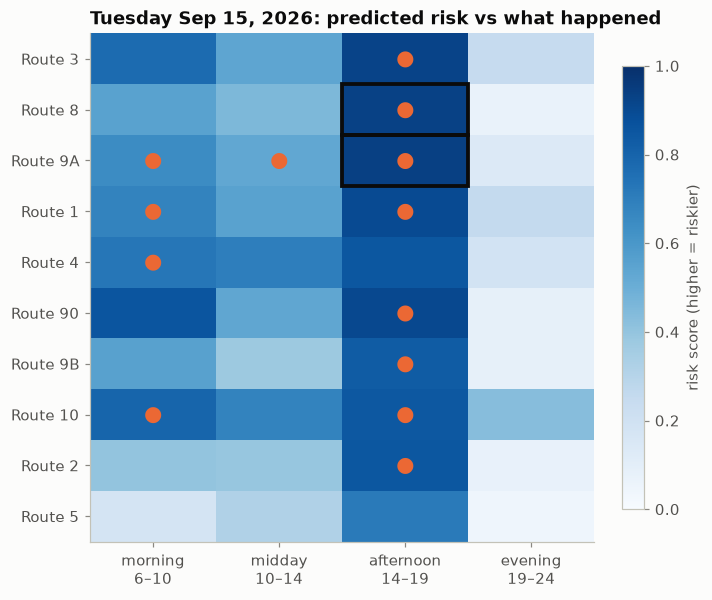

Overload cells that day: 13 of 40.  The 2 flagged cells: [['9A', 'PM'], ['8', 'PM']]; correct: 2 of 2


In [21]:
day = pd.Timestamp("2026-09-15")
d = test.assign(risk=S["LightGBM: everything (final)"])
d = d[d.date == day]
grid = d.pivot_table(index="route", columns="period", values="risk", observed=False).reindex(columns=["AM", "MID", "PM", "EVE"])
actual = d.pivot_table(index="route", columns="period", values="y", observed=False).reindex(columns=["AM", "MID", "PM", "EVE"])
flag = d.nlargest(2, "risk")[["route", "period"]].astype(str).values.tolist()
fig, ax = plt.subplots(figsize=(6.5, 6))
im = ax.imshow(grid.values, cmap="Blues", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(4), ["morning\n6–10", "midday\n10–14", "afternoon\n14–19", "evening\n19–24"])
ax.set_yticks(range(len(grid)), [f"Route {r}" for r in grid.index]); ax.grid(False)
for i, r in enumerate(grid.index):
    for j, p in enumerate(grid.columns):
        if actual.loc[r, p] == 1:
            ax.text(j, i, "●", ha="center", va="center", fontsize=14, color=ORANGE)
        if [str(r), p] in flag:
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=INK, lw=2.5))
ax.set_title(f"{day:%A %b %d, %Y}: predicted risk vs what happened")
fig.colorbar(im, ax=ax, fraction=0.04, label="risk score (higher = riskier)")
plt.show()
print(f"Overload cells that day: {int(d.y.sum())} of 40.  The 2 flagged cells: {flag}; correct: {int(d.nlargest(2, 'risk').y.sum())} of 2")

**How to read it.** The dark cells are the model's highest-risk guesses, mostly afternoons on the busiest routes. Orange dots show where buses actually left riders behind. Most dots sit in the darker cells, so the model has learned the shape of the problem, though it doesn't catch every one.

## 14. What does the model look at?

A model is more trustworthy if we can see *why* it predicts what it does. **SHAP values** measure how much each clue pushes each prediction up or down. Averaging their size gives each clue's overall importance. We compute them on the 2025 validation year.

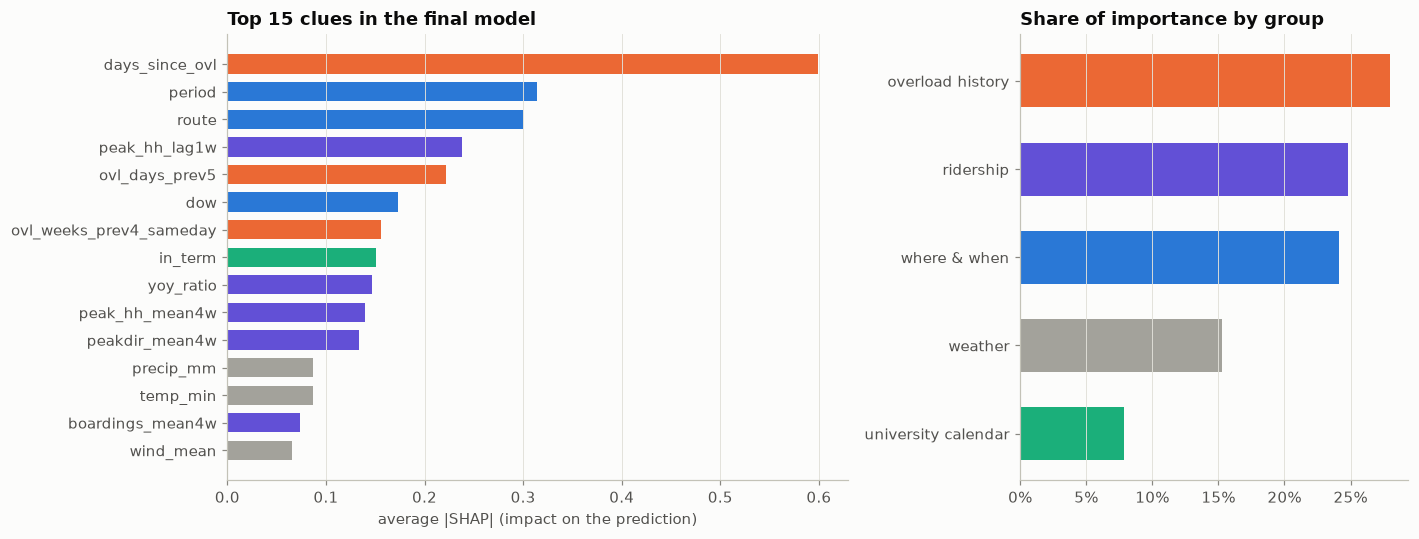

In [22]:
contrib = final_model.booster_.predict(val[final_features], pred_contrib=True)[:, :-1]
imp = pd.Series(np.abs(contrib).mean(axis=0), index=final_features)
group_of = {f: "where & when" if f in TIME else "overload history" if f in HISTORY else "university calendar" if f in CALENDAR
            else "ridership" if f in RIDERSHIP else "weather" for f in final_features}
gcol = {"where & when": BLUE, "overload history": ORANGE, "ridership": VIOLET, "university calendar": AQUA, "weather": GRAY}
top = imp.sort_values().tail(15)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})
a1.barh(top.index, top.values, height=0.7, color=[gcol[group_of[f]] for f in top.index])
a1.grid(axis="y", visible=False); a1.grid(axis="x", visible=True); a1.set_xlabel("average |SHAP| (impact on the prediction)")
a1.set_title("Top 15 clues in the final model")
share = (imp.groupby(group_of).sum() / imp.sum()).sort_values()
a2.barh(share.index, share.values, height=0.6, color=[gcol[g] for g in share.index])
a2.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); a2.grid(axis="y", visible=False); a2.grid(axis="x", visible=True)
a2.set_title("Share of importance by group")
fig.tight_layout(); plt.show()

**What this tells us**
- **The single most important clue is "days since the last overload" on that route and period.** After that come the period, the route, last week's busiest half-hour and the number of recent overload days.
- **The model *uses* ridership and weather, but they barely improve the score** (section 12). Their information overlaps with route, period and month. "Used by the model" is not the same as "makes the model better".

## 15. Limitations

Honest caveats a reader should know:

- **Reported, not actual, overloads.** We only see overloads that drivers reported. The jump in reports from 2022 to 2023 could partly be a change in reporting habits, and "overload history" might partly capture which routes report more.
- **The test year has been seen before.** We looked at 2026 results in earlier rounds of the project. Every choice was made on 2025, and each feature set was scored on 2026 only once, but 2026 is no longer perfectly "unseen".
- **One weather station,** at the airport, 30 km from downtown, with daily rather than hourly precipitation.
- **Calendar proxy.** We used Dalhousie's dates for all universities. A faculty lockout delayed most Dal classes in fall 2025 (our validation year).
- **Rankings, not probabilities.** Class weighting makes the risk scores good for *ranking* but too high as actual probabilities. They would need recalibrating before being read as "X% chance".
- **Ten routes, weekdays only,** grouped into 4 periods; nothing here predicts individual bus trips.

## 16. Results at a glance

Everything we tried, in one table. All scores are on the **2026 test year**, which the models never trained on.
- **Gain** is the change in PR-AUC compared with the where-and-when model, with its 95% bootstrap interval (section 12).
- **Helps** means the whole interval is above zero; **no clear effect** means the interval includes zero.

In [23]:
S, base = scores["test"], "LightGBM A: where & when"
R = {r["model"]: r for r in results["test"]}
tried = [  # (row label, model name, what it is)
    ("Rule: random guessing", "Random guessing", "pick cells at random"),
    ("Rule: same as last week", "Same as last week", "was there an overload here last week?"),
    ("Rule: historical rate", "Historical rate", "how often it happened here before (same month)"),
    ("Where & when", base, "route, time period, day of week, month"),
    ("+ recent ridership", "LightGBM: + recent ridership", "boardings last week and over the last 4 weeks"),
    ("+ weather", "LightGBM: + ridership + weather", "rain, snow, wind, temperature (added on top of recent ridership)"),
    ("+ university calendar", "LightGBM: + university calendar", "term weeks, study breaks, exam periods"),
    ("+ better ridership", "LightGBM: + better ridership", "busiest half-hour, busier direction, growth, 'busier than usual'"),
    ("+ overload history", "LightGBM: + overload history", "overloads here in the last days and weeks"),
    ("+ all three new ideas", "LightGBM: + all three", "history + calendar + better ridership"),
    ("Everything (final model)", "LightGBM: everything (final)", "all of the above + weather"),
]
rows = []
for label, name, what in tried:
    if name == base:
        g, lo, hi = bootstrap_gain(test, S["Historical rate"], S[base])
        gain, verdict = "–", f"beats the best rule (+{g:.3f}, CI {lo:+.3f} to {hi:+.3f})"
    elif name in ("Random guessing", "Same as last week", "Historical rate"):
        gain, verdict = "–", "simple rule"
    else:
        g, lo, hi = bootstrap_gain(test, S[base], S[name])
        gain = f"{g:+.3f}  ({lo:+.3f} to {hi:+.3f})"
        verdict = "helps" if lo > 0 else ("hurts" if hi < 0 else "no clear effect")
    rows.append({"What we tried": label, "In one line": what, "PR-AUC 2026": R[name]["PR-AUC"],
                 "Gain vs where & when (95% CI)": gain,
                 "Overloads caught by top-5% flag": f'{R[name]["overloads caught (top 5%)"]} of {R[name]["out of"]}',
                 "Flags that were right": f'{R[name]["flags that were right"]:.0%}', "Verdict": verdict})
glance = pd.DataFrame(rows)

def shade(row):
    c = "#fdeee6" if row["Verdict"] == "helps" else "#e7f1fb" if row["What we tried"] == "Where & when" else "#f0efec" if row["Verdict"] == "simple rule" else ""
    return [f"background-color: {c}" if c else "" for _ in row]
(glance.style.apply(shade, axis=1).hide(axis="index").format({"PR-AUC 2026": "{:.3f}"})
       .set_properties(**{"text-align": "left"}).set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

What we tried,In one line,PR-AUC 2026,Gain vs where & when (95% CI),Overloads caught by top-5% flag,Flags that were right,Verdict
Rule: random guessing,pick cells at random,0.084,–,44 of 656,11%,simple rule
Rule: same as last week,was there an overload here last week?,0.141,–,129 of 656,31%,simple rule
Rule: historical rate,how often it happened here before (same month),0.249,–,135 of 656,32%,simple rule
Where & when,"route, time period, day of week, month",0.292,–,159 of 656,38%,"beats the best rule (+0.043, CI +0.029 to +0.059)"
+ recent ridership,boardings last week and over the last 4 weeks,0.287,-0.005 (-0.021 to +0.013),152 of 656,36%,no clear effect
+ weather,"rain, snow, wind, temperature (added on top of recent ridership)",0.289,-0.003 (-0.020 to +0.014),154 of 656,37%,no clear effect
+ university calendar,"term weeks, study breaks, exam periods",0.299,+0.007 (-0.007 to +0.024),166 of 656,40%,no clear effect
+ better ridership,"busiest half-hour, busier direction, growth, 'busier than usual'",0.290,-0.002 (-0.019 to +0.018),153 of 656,37%,no clear effect
+ overload history,overloads here in the last days and weeks,0.360,+0.069 (+0.044 to +0.093),191 of 656,46%,helps
+ all three new ideas,history + calendar + better ridership,0.366,+0.074 (+0.045 to +0.102),192 of 656,46%,helps


**How to read it**
- **Grey rows** are the simple rules. The best of them, the historical rate, scores 0.249.
- **The blue row**, where & when, is our first real model. It beats every rule.
- **Orange rows** are the only additions that clearly help, and every one of them contains **overload history**.
- **Weather, the calendar and better ridership** all show "no clear effect": their intervals include zero.
- **The final model** catches the most overloads with its top-5% flag (194 of 656, with 47% of flags right). History alone gets almost the same result.

## 17. Conclusion

**Can we predict which routes and times will leave riders behind?** **Yes, moderately well.**
- On 2026, a year the model never trained on, the final model scores PR-AUC **0.370**. That compares with 0.249 for the best simple rule and about 0.08 for random guessing.
- Flagging the riskiest 5% of route-periods would have caught **30%** of overloads, with almost half the flags correct.

**What actually helps the prediction?**
1. **Where and when** (route, period, day, month) carries most of the signal: overloads are a *structural* problem of particular routes at particular times, especially weekday afternoons in September–October.
2. **Recent overload history** is the one extra clue that clearly helps. A route and period that keeps overloading usually has a lasting capacity shortfall, and the clue also follows each year's overall level.
3. **Weather, the university calendar and detailed ridership numbers add nothing** on top of that, even with a perfect weather forecast.

**What it means in practice.** Overload risk is mostly about *where and when*, plus *where it has just been happening*, not day-to-day demand or weather. Halifax Transit could use this kind of model as a cheap early-warning list: each day, check the few route-periods at the top of the list and add capacity there first.